In [84]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [85]:
import os
print(os.listdir('/kaggle/input'))
for root, dirs, files in os.walk('/kaggle/input'):
        print(root, files)

['competitions']
/kaggle/input []
/kaggle/input/competitions []
/kaggle/input/competitions/digit-recognizer ['sample_submission.csv', 'train.csv', 'test.csv']


In [86]:
data_train = pd.read_csv('/kaggle/input/competitions/digit-recognizer/train.csv')
data_dev = pd.read_csv('/kaggle/input/competitions/digit-recognizer/train.csv')


In [87]:
data = np.array(data_train)
m, n = data.shape
np.random.shuffle(data)

data_dev = data[:1000].T
Y_dev = data_dev[0]
X_dev = data_dev[1:n] / 255.

data_train = data[1000:].T
Y_train = data_train[0]
X_train = data_train[1:n] / 255.

In [88]:
def init_params():
    W1 = np.random.rand(10, 784) - 0.5
    b1 = np.random.rand(10, 1) - 0.5
    W2 = np.random.rand(10, 10) - 0.5
    b2 = np.random.rand(10, 1) - 0.5
    return W1, b1, W2, b2

def ReLU(Z):
    return np.maximum(0,Z)

def softmax(Z):
    A = np.exp(Z) / sum(np.exp(Z))
    return A

def forward_prop(W1, b1, W2, b2, X):
    Z1 = W1.dot(X) + b1
    A1 = ReLU(Z1)
    Z2 = W2.dot(A1) + b2
    A2 = softmax(Z2)
    return Z1, A1, Z2, A2

def one_hot(Y):
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    one_hot_Y = one_hot_Y.T
    return one_hot_Y
def deriv_ReLU(Z):
    return Z > 0

def back_prop(Z1, A1, Z2, A2, W1, W2, X, Y):
    m = Y.size
    one_hot_Y = one_hot(Y)
    dZ2 = A2 - one_hot_Y
    dW2 = 1/m * dZ2.dot(A1.T)
    db2 = 1/m * np.sum(dZ2, axis=1, keepdims=True)
    dZ1 = W2.T.dot(dZ2) * deriv_ReLU(Z1)
    dW1 = 1/m * dZ1.dot(X.T)
    db1 = 1/m * np.sum(dZ1, axis=1, keepdims=True)
    return dW1, db1, dW2, db2

def update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha):
    W1 = W1 - alpha * dW1
    b1 = b1 - alpha * db1
    W2 = W2 - alpha * dW2
    b2 = b2 - alpha * db2
    return W1, b1, W2, b2
    

In [89]:
def get_predictions(A2):
    return np.argmax(A2, 0)

def get_accuracy(predictions, Y):
    print(predictions, Y)
    return np.sum(predictions == Y) / Y.size
    

def gradient_descent(X, Y, iterations, alpha):
    W1, b1, W2, b2 = init_params()
    for i in range(iterations):
        Z1, A1, Z2, A2 = forward_prop(W1, b1, W2, b2, X)
        dW1, db1, dW2, db2 = back_prop(Z1, A1, Z2, A2, W1, W2, X, Y)
        W1, b1, W2, b2 = update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha)
        if i % 50 == 0:
            print("Iteration: ", i)
            predictions = get_predictions(A2)
            print(get_accuracy(predictions, Y))

    return W1, b1, W2, b2

In [90]:
W1, b1, W2, b2 = gradient_descent(X_train, Y_train, 500, 0.1)

Iteration:  0
[7 7 7 ... 9 9 9] [9 2 8 ... 3 3 1]
0.09024390243902439
Iteration:  50
[7 6 6 ... 3 3 1] [9 2 8 ... 3 3 1]
0.47892682926829266
Iteration:  100
[7 6 6 ... 3 3 1] [9 2 8 ... 3 3 1]
0.6393658536585366
Iteration:  150
[9 6 8 ... 3 3 1] [9 2 8 ... 3 3 1]
0.7139512195121951
Iteration:  200
[9 6 8 ... 3 3 1] [9 2 8 ... 3 3 1]
0.7571951219512195
Iteration:  250
[9 2 8 ... 3 3 1] [9 2 8 ... 3 3 1]
0.7860487804878049
Iteration:  300
[9 2 8 ... 3 3 1] [9 2 8 ... 3 3 1]
0.805439024390244
Iteration:  350
[9 2 8 ... 3 8 1] [9 2 8 ... 3 3 1]
0.8200975609756097
Iteration:  400
[9 2 8 ... 3 8 1] [9 2 8 ... 3 3 1]
0.831390243902439
Iteration:  450
[9 2 8 ... 3 8 1] [9 2 8 ... 3 3 1]
0.8394634146341463


In [91]:
def make_predictions(X, W1, b1, W2, b2):
    _, _, _, A2 = forward_prop(W1, b1, W2, b2, X)
    predictions = get_predictions(A2)
    return predictions

def test_prediction(index, W1, b1, W2, b2):
    current_image = X_train[:, index, None]
    prediction = make_predictions(X_train[:, index, None], W1, b1, W2, b2)
    label = Y_train[index]
    print("Prediction: ", prediction)
    print("Label: ", label)
    
    current_image = current_image.reshape((28, 28)) * 255
    plt.gray()
    plt.imshow(current_image, interpolation='nearest')
    plt.show()

Prediction:  [9]
Label:  9


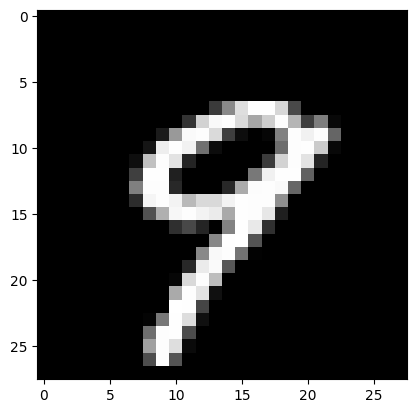

Prediction:  [2]
Label:  2


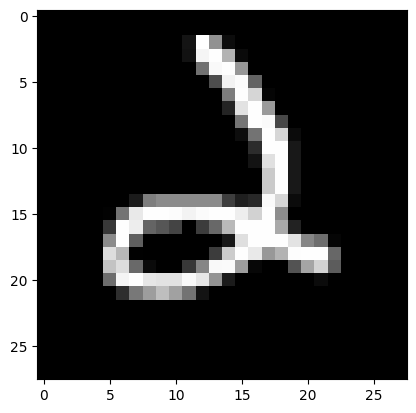

Prediction:  [8]
Label:  8


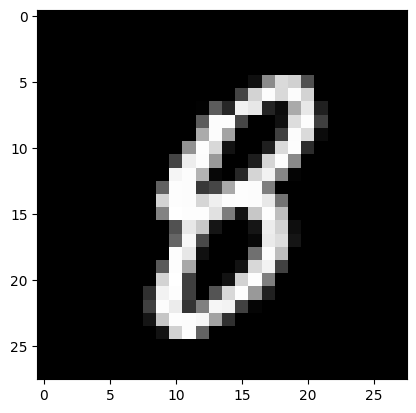

Prediction:  [3]
Label:  5


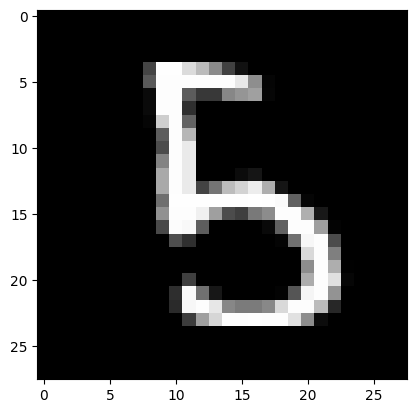

In [92]:
test_prediction(0, W1, b1, W2, b2)
test_prediction(1, W1, b1, W2, b2)
test_prediction(2, W1, b1, W2, b2)
test_prediction(3, W1, b1, W2, b2)

In [93]:
dev_predictions = make_predictions(X_dev, W1, b1, W2, b2)
get_accuracy(dev_predictions, Y_dev)

[8 1 1 3 3 1 9 4 7 2 1 3 6 7 9 5 3 6 7 1 2 7 6 4 9 9 9 7 8 7 4 3 4 1 6 4 5
 4 8 8 5 4 3 6 6 8 9 9 6 7 7 4 2 3 3 8 7 4 4 0 2 9 0 1 7 0 7 0 0 0 9 7 6 6
 0 8 6 0 1 5 3 7 4 3 3 3 9 0 7 3 2 9 7 2 4 7 7 1 6 7 5 2 3 6 4 4 3 9 8 4 7
 0 4 6 2 6 4 2 5 0 1 7 5 7 1 5 7 9 5 9 8 1 1 2 1 0 9 5 5 5 8 0 9 9 7 3 9 6
 9 5 4 0 5 6 9 8 9 2 9 1 2 4 5 7 9 7 8 8 6 6 2 7 3 8 4 6 9 6 0 0 9 9 5 2 8
 8 6 9 2 2 1 5 2 2 3 3 3 0 4 1 8 8 2 3 6 0 7 0 8 4 5 3 7 9 1 4 7 2 1 6 8 8
 2 0 5 5 1 8 4 1 4 7 1 6 3 1 3 6 7 2 5 8 8 5 8 1 7 5 7 9 6 3 9 0 6 1 3 0 9
 0 1 1 6 2 0 8 7 7 7 5 9 7 1 0 4 3 5 7 6 3 5 2 3 6 3 8 9 3 1 2 9 2 5 2 1 9
 7 1 3 2 9 6 7 0 3 5 8 5 6 3 0 3 9 8 4 7 8 4 6 2 7 5 7 2 8 6 7 0 1 2 9 4 5
 1 4 8 9 7 6 2 0 2 0 8 4 0 5 1 9 3 3 7 8 5 6 9 6 8 7 6 6 6 2 1 3 5 5 2 8 3
 7 6 0 8 2 9 8 4 0 4 0 6 6 7 7 7 1 8 8 3 4 9 3 5 4 1 0 7 5 6 8 2 6 2 7 0 1
 7 8 9 7 7 0 6 6 1 6 1 9 4 1 0 5 4 0 5 2 3 1 2 3 3 2 5 9 9 6 2 5 2 4 1 1 6
 5 3 4 2 5 1 6 7 1 8 7 0 3 4 3 5 8 9 7 4 3 9 1 7 9 9 4 8 3 2 4 4 1 9 4 0 0
 7 6 6 7 8 3 9 8 3 7 2 0 

np.float64(0.858)